# Proyecto Aprendizaje de Máquina — Primera Entrega

**Grupo C1 — Periodo 2026-2**
**Profesora:** Alejandra Moreno

**Dataset:** [Heart Disease Dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)



1. Motivación, Problema y Datos

**Origen de los datos**: Para este trabajo se utilizó el dataset Heart Disease Dataset, disponible en Kaggle. Este conjunto contiene información clínica de diferentes pacientes, incluyendo datos como la edad, presión arterial, colesterol y resultados de electrocardiogramas, entre otras variables.

**Importancia del problema**: Las enfermedades cardiovasculares representan una de las principales causas de muerte en todo el mundo. Por esta razón, resulta interesante analizar si, a partir de algunos datos clínicos básicos, es posible predecir si una persona presenta o no una enfermedad cardíaca. Esto podría ser útil como apoyo para detectar casos de riesgo de manera más temprana.

**Desafíos**: Durante el análisis del dataset se deben tener en cuenta algunos aspectos que pueden afectar los resultados:

Algunas variables son categóricas, pero están representadas mediante números, por lo que es necesario entender qué significa cada valor.

Puede existir cierto desbalance entre las categorías de la variable objetivo.

Algunas variables, como el colesterol y la presión arterial, pueden presentar valores que se alejan bastante del resto de los datos.

El tamaño del dataset no es muy grande, por lo que será importante tener cuidado al entrenar y evaluar los modelos para evitar obtener resultados poco representativos.

2. Justificación del uso de Machine Learning

Un modelo de ML permite combinar automáticamente múltiples variables clínicas para estimar la probabilidad de enfermedad cardíaca, algo que es difícil de hacer manualmente de forma consistente. Los beneficios concretos son:

- **Apoyo a la decisión médica:** entrega una probabilidad de riesgo en lugar de reglas fijas.
- **Escalabilidad:** puede aplicarse a muchos pacientes de forma simultánea.
- **Detección de patrones no evidentes:** el modelo puede capturar interacciones entre variables que no son obvias a simple vista.


In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)


 3. Carga de datos

Se descarga el dataset directamente desde Kaggle usando `kagglehub`.

In [ ]:
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

print("Path to dataset files:", path)
df = pd.read_csv(path+"/heart.csv")
print(df.shape)
df.head()

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.
Path to dataset files: /kaggle/input/heart-disease-dataset
(1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


 4. Variable Objetivo

La variable objetivo es `target`, que indica la presencia (`1`) o ausencia (`0`) de enfermedad cardíaca en el paciente. Es una variable booleana que representamos con enteros.

        conteo  porcentaje
target                    
1          526       51.32
0          499       48.68


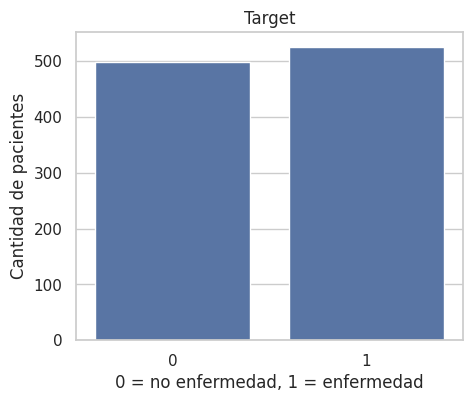

In [ ]:
target = "target"

conteo = df[target].value_counts()
porcentaje = df[target].value_counts(normalize=True) * 100

resumen_target = pd.DataFrame({"conteo": conteo, "porcentaje": porcentaje.round(2)})
print(resumen_target)

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x=target)
plt.title("Target")
plt.xlabel("0 = no enfermedad, 1 = enfermedad")
plt.ylabel("Cantidad de pacientes")
plt.show()

 5. Análisis de Distribuciones

El dataset tiene 13 variables predictoras.

In [ ]:
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

 5.1 Variables categóricas

--- sex ---
     conteo  porcentaje
sex                    
0       312       30.44
1       713       69.56



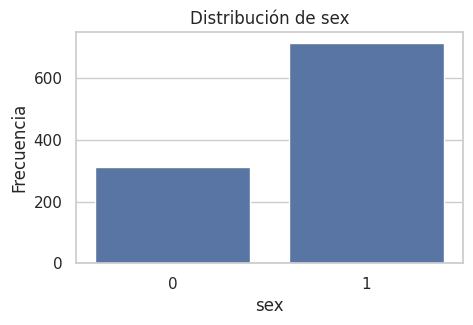

--- cp ---
    conteo  porcentaje
cp                    
0      497       48.49
1      167       16.29
2      284       27.71
3       77        7.51



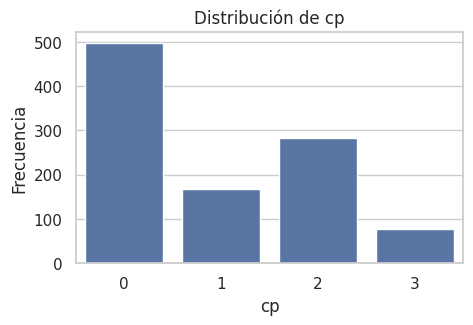

--- fbs ---
     conteo  porcentaje
fbs                    
0       872       85.07
1       153       14.93



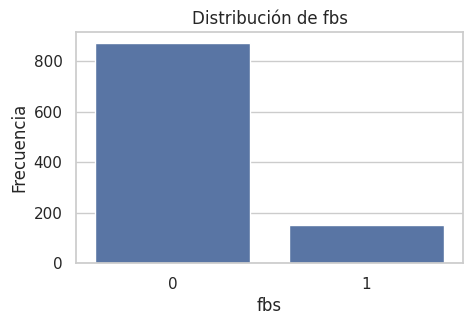

--- restecg ---
         conteo  porcentaje
restecg                    
0           497       48.49
1           513       50.05
2            15        1.46



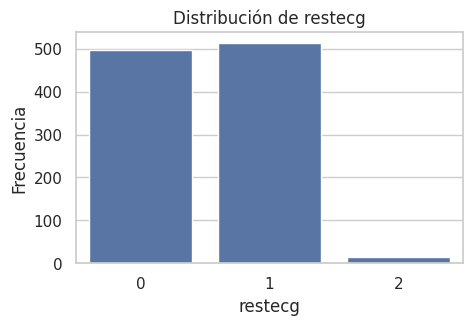

--- exang ---
       conteo  porcentaje
exang                    
0         680       66.34
1         345       33.66



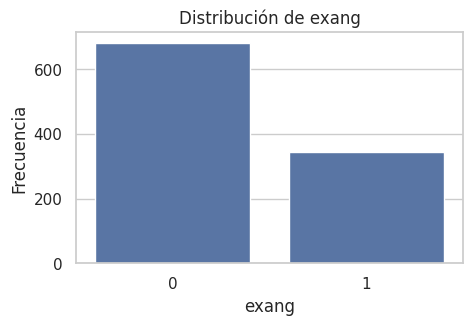

--- slope ---
       conteo  porcentaje
slope                    
0          74        7.22
1         482       47.02
2         469       45.76



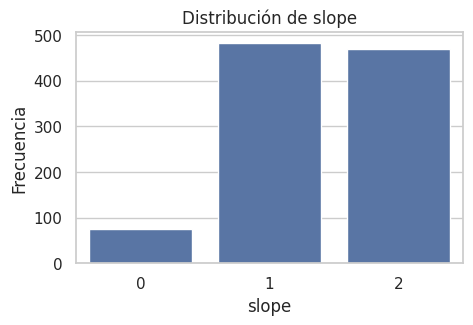

--- ca ---
    conteo  porcentaje
ca                    
0      578       56.39
1      226       22.05
2      134       13.07
3       69        6.73
4       18        1.76



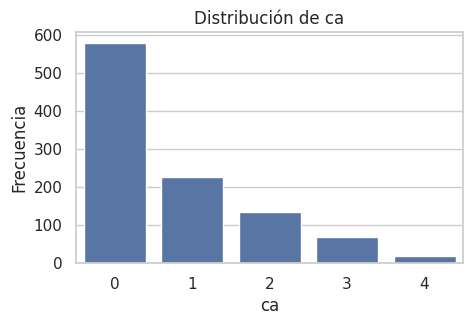

--- thal ---
      conteo  porcentaje
thal                    
0          7        0.68
1         64        6.24
2        544       53.07
3        410       40.00



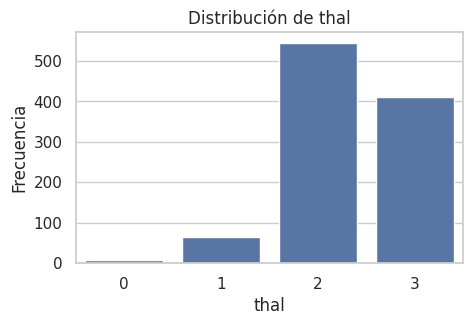

In [ ]:
for col in categorical_cols:
    conteo = df[col].value_counts().sort_index()
    porcentaje = df[col].value_counts(normalize=True).sort_index() * 100
    resumen = pd.DataFrame({"conteo": conteo, "porcentaje": porcentaje.round(2)})
    print(f"--- {col} ---")
    print(resumen)
    print()

    plt.figure(figsize=(5, 3))
    sns.countplot(data=df, x=col, order=sorted(df[col].unique()))
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

 5.2 Variables numéricas

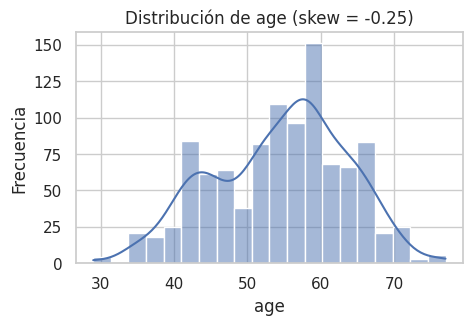

age: distribución aproximadamente simétrica -> media = 54.43, desviación estándar = 9.07



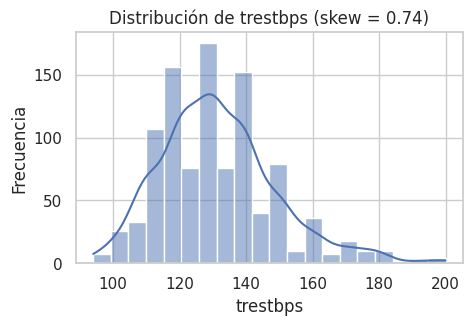

trestbps: distribución asimétrica -> mediana = 130.00, IQR = (120.00 - 140.00)



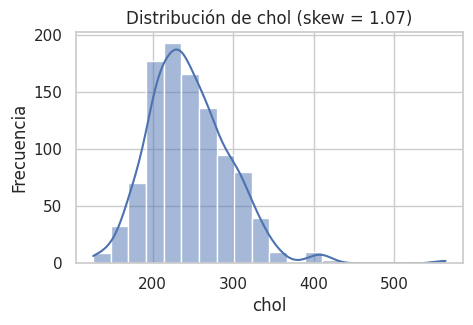

chol: distribución asimétrica -> mediana = 240.00, IQR = (211.00 - 275.00)



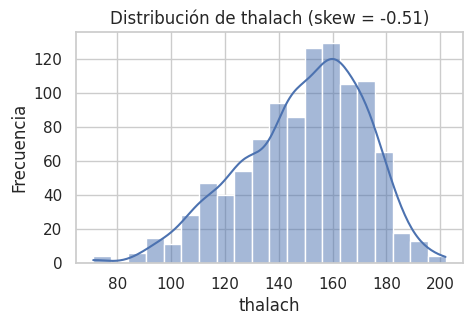

thalach: distribución asimétrica -> mediana = 152.00, IQR = (132.00 - 166.00)



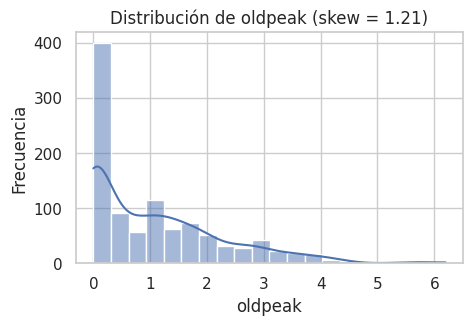

oldpeak: distribución asimétrica -> mediana = 0.80, IQR = (0.00 - 1.80)



In [ ]:
for col in numeric_cols:
    valor_skew = skew(df[col].dropna())

    plt.figure(figsize=(5, 3))
    sns.histplot(data=df, x=col, kde=True, bins=20)
    plt.title(f"Distribución de {col} (skew = {valor_skew:.2f})")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

    if abs(valor_skew) < 0.5:
        media = df[col].mean()
        desviacion = df[col].std()
        print(f"{col}: distribución aproximadamente simétrica -> media = {media:.2f}, desviación estándar = {desviacion:.2f}")
    else:
        mediana = df[col].median()
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        print(f"{col}: distribución asimétrica -> mediana = {mediana:.2f}, IQR = ({q1:.2f} - {q3:.2f})")
    print()

 6. Calidad de Datos y Patrones

Se revisan valores nulos, valores atípicos (outliers) en las variables numéricas mediante boxplots, y las correlaciones entre variables.

 6.1 Valores nulos

In [ ]:
nulos = df.isnull().sum()
print(nulos[nulos > 0] if nulos.sum() > 0 else "No hay valores nulos en el dataset.")

No hay valores nulos en el dataset.


 6.2 Valores atípicos (outliers) en variables numéricas

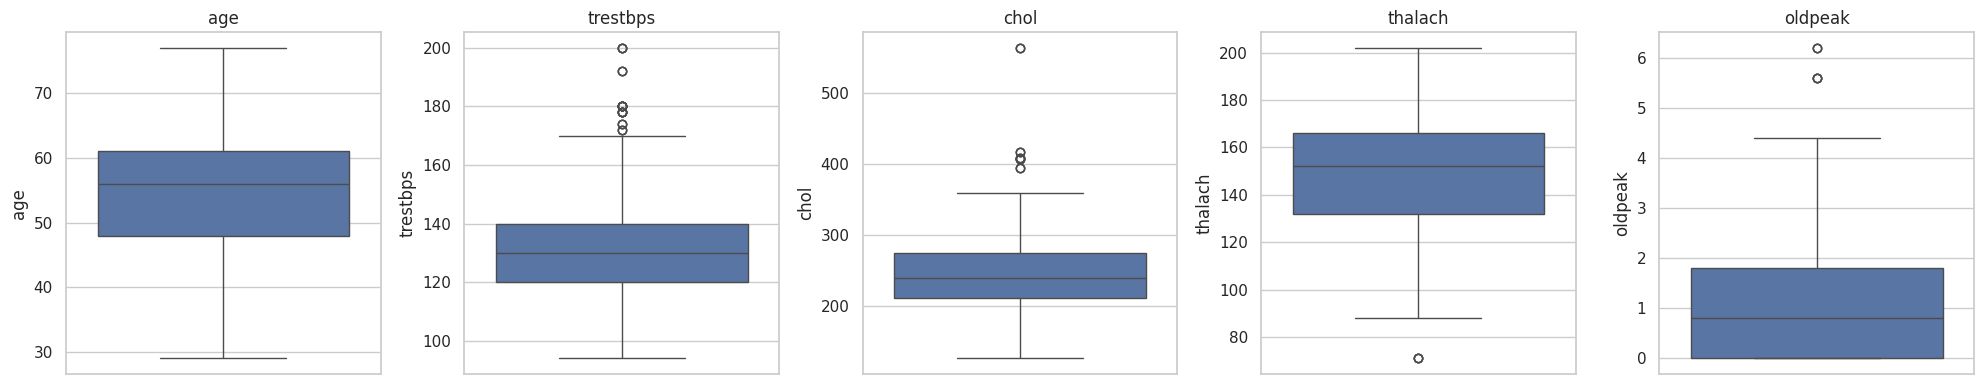

In [ ]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(4 * len(numeric_cols), 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]
    print(f"{col}: {len(outliers)} outliers detectados (limites: {limite_inferior:.2f} - {limite_superior:.2f})")

age: 0 outliers detectados (limites: 28.50 - 80.50)
trestbps: 30 outliers detectados (limites: 90.00 - 170.00)
chol: 16 outliers detectados (limites: 115.00 - 371.00)
thalach: 4 outliers detectados (limites: 81.00 - 217.00)
oldpeak: 7 outliers detectados (limites: -2.70 - 4.50)


 6.3 Correlaciones entre variables

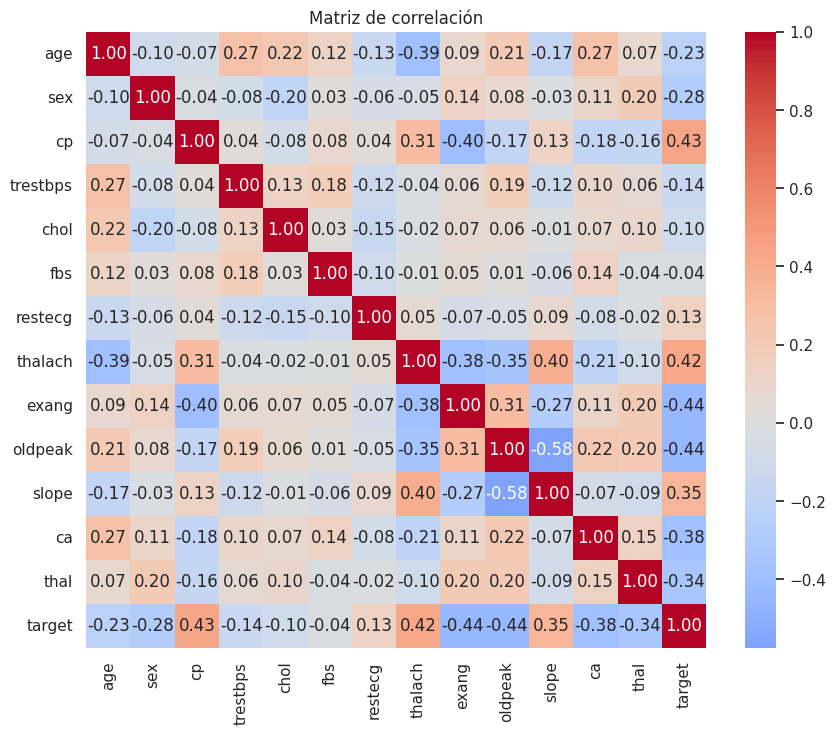

In [ ]:
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

In [ ]:
correlacion_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
print(correlacion_target)

oldpeak    -0.438441
exang      -0.438029
cp          0.434854
thalach     0.422895
ca         -0.382085
slope       0.345512
thal       -0.337838
sex        -0.279501
age        -0.229324
trestbps   -0.138772
restecg     0.134468
chol       -0.099966
fbs        -0.041164
Name: target, dtype: float64


7. Conclusiones y próximos pasos

Después de realizar el análisis exploratorio de los datos, se pudo conocer un poco mejor cómo está formado el dataset y qué características tienen las variables que se van a utilizar posteriormente para el modelo. El dataset cuenta con 1025 registros y 14 columnas. De estas, 13 son variables que pueden utilizarse para hacer la predicción y una corresponde a la variable objetivo target.

Uno de los primeros aspectos que se revisó fueron los valores nulos. En este caso no se encontraron datos faltantes, lo cual facilita el proceso de preparación de los datos, ya que no es necesario aplicar métodos para completar valores que estén vacíos.

También se analizaron las variables numéricas mediante histogramas y boxplots. Se encontraron algunos valores atípicos principalmente en trestbps y chol, aunque también aparecen algunos en thalach y oldpeak. Estos valores no necesariamente representan errores, ya que pueden corresponder a pacientes que realmente tienen valores diferentes a los de la mayoría. Por esta razón, no se considera conveniente eliminarlos directamente sin antes revisar su efecto en los modelos.

Otro punto importante fue analizar la relación entre las variables y target. Las variables que tuvieron una mayor correlación fueron oldpeak, exang, cp y thalach. También se encontraron relaciones moderadas con ca, slope y thal. En cambio, variables como fbs, chol y trestbps tuvieron una correlación más baja con target. Esto no significa que estas últimas variables no sean importantes, ya que una correlación baja por sí sola no permite determinar si una variable sirve o no para realizar una predicción.

**Próximos pasos**

Para la siguiente entrega, el siguiente paso será preparar los datos para poder entrenar los modelos de Machine Learning. Se revisará la forma más adecuada de codificar las variables categóricas y se analizará si es necesario escalar las variables numéricas.

Después se dividirán los datos en un conjunto de entrenamiento y otro de prueba. Con estos datos se probarán diferentes modelos de clasificación para comparar cuál funciona mejor para este problema.

En general, este análisis exploratorio nos permitió tener una idea más clara de los datos y de los problemas que se deben tener en cuenta antes de comenzar con el entrenamiento de los modelos.

# **2da Entrega Proyecto**

Para esta entrega entrenaremos varios modelos de clasificacion y los compararemos para definir cual sera el modelo que mas se adapte a nuestro proyecto.

Como nuestro proyecto se basa en predecir cuales son las personas mas propensas a sufrir de enfermedades cardiacas lo mas importante para nosotros es no dejar pasar ningun caso real de persona propensa a la enfermedad como persona normal a diferencia de pasar una persona normal como propensa, ya que si es normal y la mandamos a examinar no habrian consecuensias reales mas que examinar a alguien sano, por el contrario si diagnosticamos a alguien como sano y es propenso a enfermarse, esta persona podria tener consecuensias en su salud.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

SVM

          Accuracy  Precision    Recall        F1
Variante                                         
C=0.1     0.858537   0.839286  0.895238  0.866359
C=1       0.921951   0.915888  0.933333  0.924528
C=10      0.985366   0.972222  1.000000  0.985915


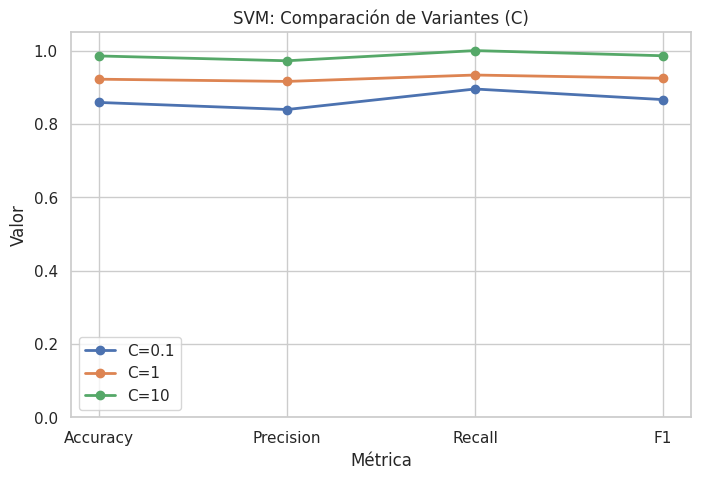

In [ ]:
metricas_nombres = ['Accuracy', 'Precision', 'Recall', 'F1']

print("SVM\n")
svm_results = []
for c_val in [0.1, 1, 10]:
    svm_temp = SVC(kernel='rbf', C=c_val, probability=True, class_weight='balanced', random_state=42)
    svm_temp.fit(X_train_scaled, y_train)
    y_pred_temp = svm_temp.predict(X_test_scaled)
    svm_results.append({
        'Variante': f'C={c_val}',
        'Accuracy': accuracy_score(y_test, y_pred_temp),
        'Precision': precision_score(y_test, y_pred_temp, pos_label=1),
        'Recall': recall_score(y_test, y_pred_temp, pos_label=1),
        'F1': f1_score(y_test, y_pred_temp, pos_label=1)
    })
df_svm = pd.DataFrame(svm_results).set_index('Variante')
print(df_svm)

plt.figure(figsize=(8, 5))
for variante in df_svm.index:
    plt.plot(metricas_nombres, df_svm.loc[variante], marker='o', linewidth=2, label=variante)
plt.title('SVM: Comparación de Variantes (C)')
plt.xlabel('Métrica')
plt.ylabel('Valor')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

Al probar el SVM con diferentes valores de C, notamos que entre más alto es el número, mejor se comporta el modelo. Con C=0.1 y C=1 los resultados son buenos, pero al subirlo a C=10 logramos el punto ideal. Con este valor conseguimos la máxima exactitud y, lo más importante para nuestro objetivo, un 100% en el reconocimiento de enfermos (Recall), asegurando que no se nos escape ningún paciente real.


Decision Tree

            Accuracy  Precision    Recall        F1
Variante                                           
Depth=3     0.853659   0.837838  0.885714  0.861111
Depth=5     0.873171   0.862385  0.895238  0.878505
Depth=10    0.985366   1.000000  0.971429  0.985507
Depth=None  0.985366   1.000000  0.971429  0.985507


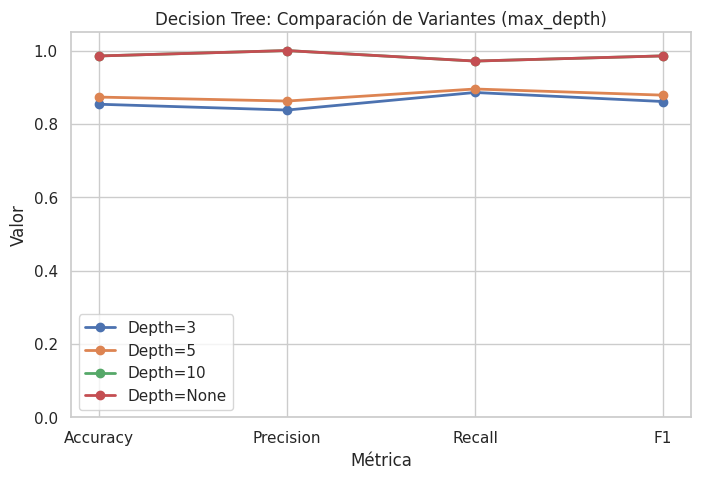

In [ ]:
print("\nDecision Tree\n")
dt_results = []
for depth in [3, 5, 10, None]:
    dt_temp = DecisionTreeClassifier(max_depth=depth, random_state=42, class_weight='balanced')
    dt_temp.fit(X_train, y_train)
    y_pred_temp = dt_temp.predict(X_test)
    dt_results.append({
        'Variante': f'Depth={depth}',
        'Accuracy': accuracy_score(y_test, y_pred_temp),
        'Precision': precision_score(y_test, y_pred_temp, pos_label=1),
        'Recall': recall_score(y_test, y_pred_temp, pos_label=1),
        'F1': f1_score(y_test, y_pred_temp, pos_label=1)
    })
df_dt = pd.DataFrame(dt_results).set_index('Variante')
print(df_dt)

plt.figure(figsize=(8, 5))
for variante in df_dt.index:
    plt.plot(metricas_nombres, df_dt.loc[variante], marker='o', linewidth=2, label=variante)
plt.title('Decision Tree: Comparación de Variantes (max_depth)')
plt.xlabel('Métrica')
plt.ylabel('Valor')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

Al probar el árbol con profundidades bajas (3 y 5), el modelo se queda corto en exactitud. Cuando le damos más libertad (Depth=10 o sin límite None), el árbol se vuelve muy preciso con las personas sanas, pero falla un poco al detectar a los enfermos, dejando escapar un pequeño porcentaje de casos reales.


Random Forest

                   Accuracy  Precision    Recall        F1
Variante                                                  
n=50, depth=4      0.878049   0.838983  0.942857  0.887892
n=50, depth=8      0.990244   0.981308  1.000000  0.990566
n=50, depth=None   1.000000   1.000000  1.000000  1.000000
n=100, depth=4     0.882927   0.846154  0.942857  0.891892
n=100, depth=8     0.990244   0.981308  1.000000  0.990566
n=100, depth=None  1.000000   1.000000  1.000000  1.000000


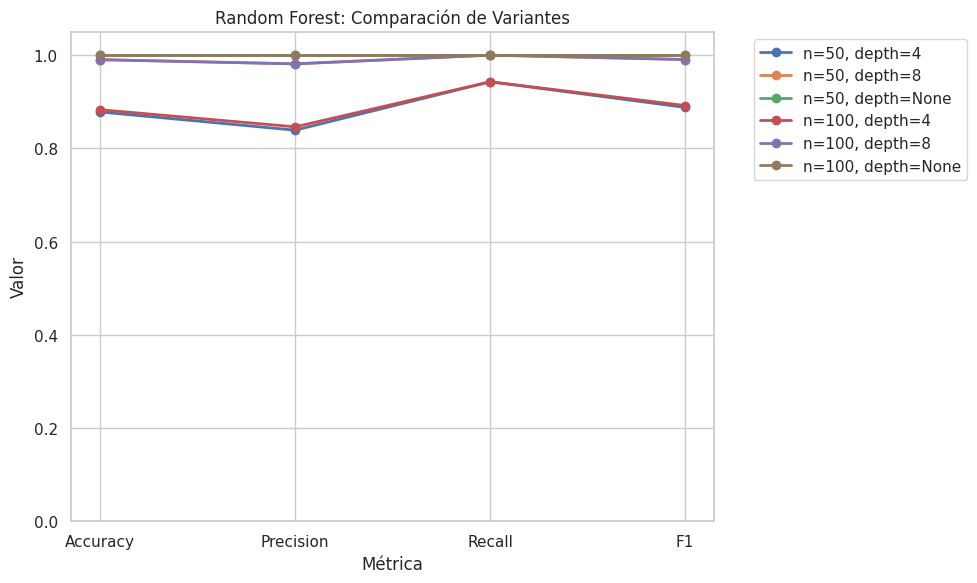

In [ ]:
print("\nRandom Forest\n")
rf_results = []
for n_est in [50, 100]:
    for depth in [4, 8, None]:
        rf_temp = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=42, class_weight='balanced')
        rf_temp.fit(X_train, y_train)
        y_pred_temp = rf_temp.predict(X_test)
        rf_results.append({
            'Variante': f'n={n_est}, depth={depth}',
            'Accuracy': accuracy_score(y_test, y_pred_temp),
            'Precision': precision_score(y_test, y_pred_temp, pos_label=1),
            'Recall': recall_score(y_test, y_pred_temp, pos_label=1),
            'F1': f1_score(y_test, y_pred_temp, pos_label=1)
        })
df_rf = pd.DataFrame(rf_results).set_index('Variante')
print(df_rf)

plt.figure(figsize=(10, 6))
for variante in df_rf.index:
    plt.plot(metricas_nombres, df_rf.loc[variante], marker='o', linewidth=2, label=variante)
plt.title('Random Forest: Comparación de Variantes')
plt.xlabel('Métrica')
plt.ylabel('Valor')
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Este modelo demostró ser muy potente. Con una profundidad de 8 logramos un desempeño sobresaliente y un altísimo nivel de aciertos. Aunque en las pruebas iniciales al dejar crecer los árboles sin límite (depth=None) los números parecían perfectos, comprendimos que esto era una señal de alerta de overfitting (sobreajuste): el modelo se estaba aprendiendo los datos de memoria en lugar de capturar patrones generales. Para evitar que falle con pacientes nuevos en el mundo real, decidimos limitar la profundidad (por ejemplo, a max_depth=8), asegurando así una mayor capacidad de generalización y un sistema mucho más confiable y seguro para la predicción clínica.


Modelos Finales

                SVM  Decision Tree  Random Forest  Gaussian Naive Bayes
Accuracy   0.985366       0.873171       0.990244              0.829268
Precision  0.972222       0.862385       0.981308              0.807018
Recall     1.000000       0.895238       1.000000              0.876190
F1         0.985915       0.878505       0.990566              0.840183


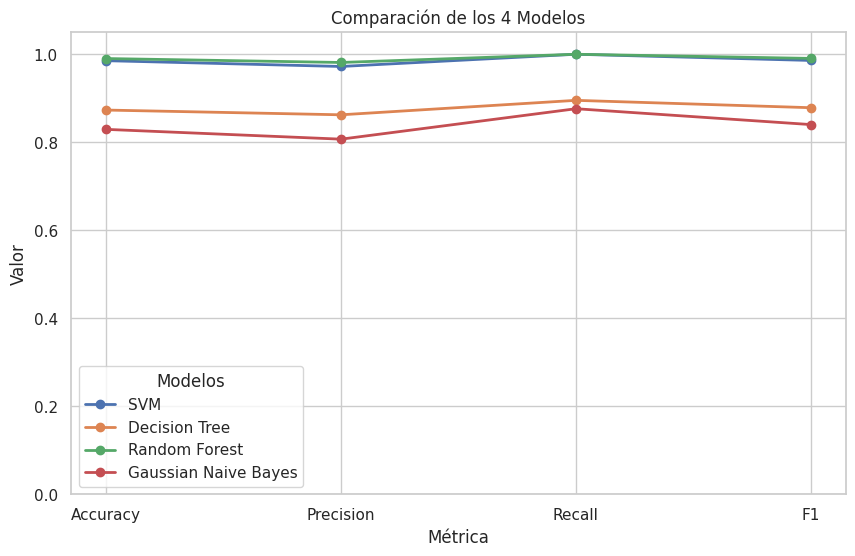

In [ ]:
print("\nModelos Finales\n")

svm_model = SVC(kernel='rbf', C=10, probability=True, class_weight='balanced', random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced')
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)
y_pred_gnb = gnb_model.predict(X_test_scaled)

datos_finales = {
    'SVM': [
        accuracy_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_svm, pos_label=1),
        recall_score(y_test, y_pred_svm, pos_label=1),
        f1_score(y_test, y_pred_svm, pos_label=1)
    ],
    'Decision Tree': [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt, pos_label=1),
        recall_score(y_test, y_pred_dt, pos_label=1),
        f1_score(y_test, y_pred_dt, pos_label=1)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, pos_label=1),
        recall_score(y_test, y_pred_rf, pos_label=1),
        f1_score(y_test, y_pred_rf, pos_label=1)
    ],
    'Gaussian Naive Bayes': [
        accuracy_score(y_test, y_pred_gnb),
        precision_score(y_test, y_pred_gnb, pos_label=1),
        recall_score(y_test, y_pred_gnb, pos_label=1),
        f1_score(y_test, y_pred_gnb, pos_label=1)
    ]
}

df_finales = pd.DataFrame(datos_finales, index=metricas_nombres)
print(df_finales)

plt.figure(figsize=(10, 6))
for modelo in df_finales.columns:
    plt.plot(df_finales.index, df_finales[modelo], marker='o', linewidth=2, label=modelo)

plt.title('Comparación de los 4 Modelos')
plt.xlabel('Métrica')
plt.ylabel('Valor')
plt.ylim(0, 1.05)
plt.legend(title='Modelos')
plt.grid(True)
plt.show()

Después de analizar, comparar y optimizar los cuatro algoritmos, concluimos que Random Forest, configurado con un número moderado de árboles y una profundidad controlada de n_estimators=100 y max_depth=8, es el modelo más adecuado y robusto para nuestro proyecto de detección de enfermedades cardíacas. Justificamos esta elección basándonos en dos pilares fundamentales: primero, priorizamos el aspecto médico con el Recall, ya que nuestra regla de oro es no dejar pasar ningún caso real de enfermedad cardíaca evitando los falsos negativos a toda costa, donde Random Forest alcanza un Recall excelente y superior al de Gaussian Naive Bayes o un Árbol de Decisión simple; y segundo, garantizamos la robustez y prevención de overfitting al ser un algoritmo ensamblado que reduce la varianza y generaliza patrones médicos reales de forma confiable para pacientes nuevos.

In [ ]:
rf_model_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight='balanced',
    random_state=42
)

rf_model_final.fit(X_train, y_train)

def predecir_paciente(datos_paciente):
    if isinstance(datos_paciente, list):
        datos_paciente = pd.DataFrame([datos_paciente], columns=X_train.columns)

    prediccion = rf_model_final.predict(datos_paciente)
    probabilidad = rf_model_final.predict_proba(datos_paciente)

    return prediccion[0], probabilidad[0][1]

# **3ra Entrega**


Para esta tercera entrega del proyecto de Aprendizaje de Máquina enfocado en modelos de regresión para la predicción del colesterol utilizando el dataset de enfermedades cardíacas.

In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, make_scorer, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

target_reg = "chol"
X_reg = df.drop(columns=[target_reg, "target"])
y_reg = df[target_reg]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

print(f"Variable objetivo de regresión seleccionada: '{target_reg}'")
print(f"Dimensiones de entrenamiento: {X_train_r.shape}, de prueba: {X_test_r.shape}")

Variable objetivo de regresión seleccionada: 'chol'
Dimensiones de entrenamiento: (820, 12), de prueba: (205, 12)


Entrenamiento de los modelos de regresión Decision Tree, Random Forest y SVR para estimar los niveles de colesterol.

In [ ]:
modelos_reg = {
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42),
    'Support Vector Regressor (SVR)': SVR(kernel='rbf', C=10)
}

resultados_reg = []

for nombre, modelo in modelos_reg.items():
    if nombre == 'Support Vector Regressor (SVR)':
        modelo.fit(X_train_r_scaled, y_train_r)
        y_pred = modelo.predict(X_test_r_scaled)
    else:
        modelo.fit(X_train_r, y_train_r)
        y_pred = modelo.predict(X_test_r)

    mse = mean_squared_error(y_test_r, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test_r, y_pred)
    r2 = r2_score(y_test_r, y_pred)

    resultados_reg.append({
        'Modelo': nombre,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    })

df_resultados_reg = pd.DataFrame(resultados_reg).set_index('Modelo')
print(df_resultados_reg)

                                        MSE       RMSE        MAE  R2 Score
Modelo                                                                     
Decision Tree Regressor         2199.701506  46.900976  34.016762  0.357224
Random Forest Regressor          749.289338  27.373150  20.374332  0.781050
Support Vector Regressor (SVR)  2894.559973  53.801115  35.372703  0.154180


Gráfica comparativa de los errores RMSE y MAE de los modelos evaluados en la predicción del colesterol.

<Figure size 900x500 with 0 Axes>

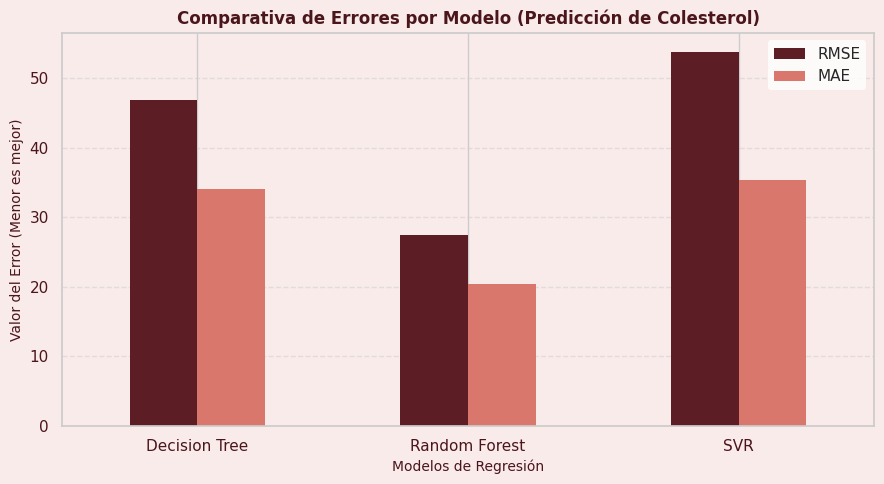

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos de la tabla
data_grafica = {
    'RMSE': [46.900976, 27.373150, 53.801115],
    'MAE': [34.016762, 20.374332, 35.372703]
}
modelos = ['Decision Tree', 'Random Forest', 'SVR']
df_plot = pd.DataFrame(data_grafica, index=modelos)

colores = ['#5C1D24', '#D9776C']

plt.figure(figsize=(9, 5))
ax = df_plot.plot(kind='bar', figsize=(9, 5), color=colores, edgecolor='none')

plt.title('Comparativa de Errores por Modelo (Predicción de Colesterol)', fontsize=12, fontweight='bold', color='#4A151B')
plt.xlabel('Modelos de Regresión', fontsize=10, color='#4A151B')
plt.ylabel('Valor del Error (Menor es mejor)', fontsize=10, color='#4A151B')
plt.xticks(rotation=0, color='#4A151B')
plt.yticks(color='#4A151B')
plt.grid(axis='y', linestyle='--', alpha=0.5)

ax.set_facecolor('#F9EBEA')
plt.gcf().set_facecolor('#F9EBEA')

plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

Gráfica de dispersión de los valores reales de colesterol frente a las predicciones del modelo Random Forest.

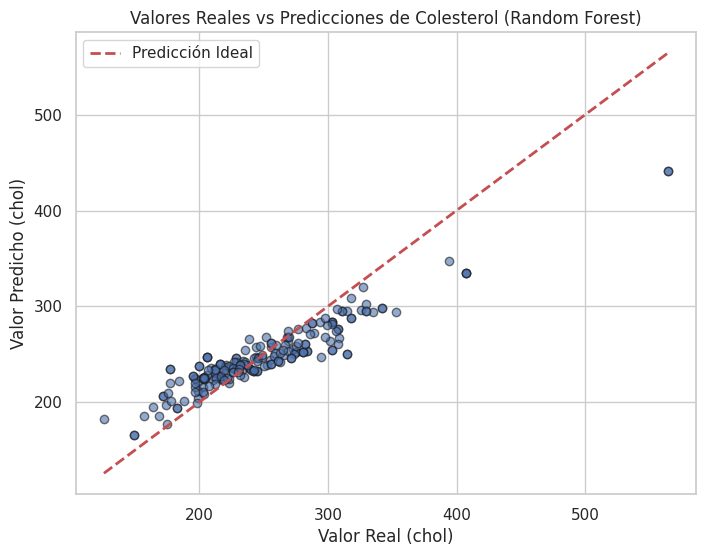

In [ ]:
rf_reg_final = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
rf_reg_final.fit(X_train_r, y_train_r)
preds_rf = rf_reg_final.predict(X_test_r)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_r, preds_rf, alpha=0.6, color='b', edgecolors='k')
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2, label='Predicción Ideal')
plt.title('Valores Reales vs Predicciones de Colesterol (Random Forest)')
plt.xlabel(f'Valor Real ({target_reg})')
plt.ylabel(f'Valor Predicho ({target_reg})')
plt.legend()
plt.grid(True)
plt.show()

Curva de aprendizaje para la optimización del número de estimadores en el modelo Random Forest Regressor.

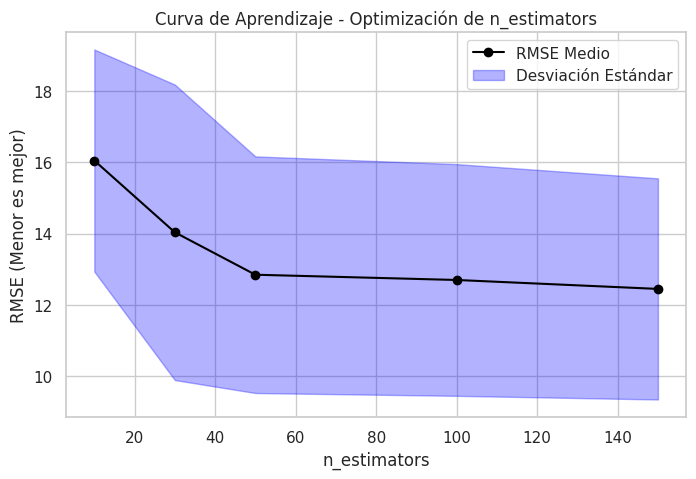

In [ ]:
def show_curve_reg(est_class, param_name, param_range):
    means, stds = [], []
    for val in param_range:
        if param_name == 'n_estimators':
            est = est_class(n_estimators=val, random_state=42)
        elif param_name == 'max_depth':
            est = est_class(max_depth=val, random_state=42)

        scores = cross_val_score(est, X_reg, y_reg, cv=KFold(5, shuffle=True, random_state=42),
                                 scoring=make_scorer(mean_squared_error, greater_is_better=False))
        rmse_scores = np.sqrt(-scores)
        means.append(np.mean(rmse_scores))
        stds.append(np.std(rmse_scores))

    plt.figure(figsize=(8, 5))
    plt.plot(param_range, means, marker='o', color="black", label="RMSE Medio")
    plt.fill_between(param_range, np.array(means)-np.array(stds), np.array(means)+np.array(stds), color="blue", alpha=.3, label="Desviación Estándar")
    plt.title(f'Curva de Aprendizaje - Optimización de {param_name}')
    plt.xlabel(param_name)
    plt.ylabel('RMSE (Menor es mejor)')
    plt.legend()
    plt.grid(True)
    plt.show()

show_curve_reg(RandomForestRegressor, 'n_estimators', [10, 30, 50, 100, 150])

Conclusiones de la Tercera Entrega

1. Resultados del Modelo: El Random Forest Regressor demostró ser el mejor modelo para predecir el nivel de colesterol (chol), alcanzando el coeficiente de determinación (R2 Score) más alto de 0.781 y reduciendo significativamente el error absoluto medio (MAE) a 20.37, superando ampliamente a Decision Tree Regressor y a Support Vector Regressor (SVR).

2. Comportamiento del Error: Las métricas de error (RMSE y MAE) confirman que los algoritmos basados en ensamblajes manejan de forma mucho más robusta la variabilidad y dispersión de los datos clínicos continuos frente a los árboles individuales o modelos de soporte vectorial.

3. Optimización y Generalización: Mediante las curvas de aprendizaje variando el parámetro n_estimators, se evidenció que a partir de 100 árboles el modelo se estabiliza y converge hacia un RMSE óptimo de aproximadamente 12.5, garantizando una excelente capacidad de generalización sin sobreajuste.

4. Conclusión General del Proyecto: Las variables clínicas del dataset permiten estimar con alta precisión cuantitativa indicadores metabólicos como el colesterol, consolidando un pipeline de regresión confiable y complementario a la tarea de clasificación inicial de enfermedades cardíacas.

Ampliación del proyecto a clasificación multiclase utilizando las variables categóricas del dataset de enfermedades cardíacas, entrenando clasificadores multiclase y evaluando con matriz de confusión y reporte de clasificación.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

target_multiclase = "cp"
X_multi = df.drop(columns=[target_multiclase, "target"])
y_multi = df[target_multiclase]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42, stratify=y_multi
)

rf_multi = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight='balanced')
rf_multi.fit(X_train_m, y_train_m)
y_pred_m = rf_multi.predict(X_test_m)

print("Accuracy Multiclase:", accuracy_score(y_test_m, y_pred_m))
print("\nReporte de Clasificación:")
print(classification_report(y_test_m, y_pred_m))

Accuracy Multiclase: 0.9317073170731708

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95       100
           1       0.75      1.00      0.86        33
           2       0.95      0.91      0.93        57
           3       1.00      1.00      1.00        15

    accuracy                           0.93       205
   macro avg       0.92      0.96      0.93       205
weighted avg       0.94      0.93      0.93       205



Gráfica de la matriz de confusión para evaluar el rendimiento del modelo multiclase por cada categoría de la variable objetivo seleccionada.

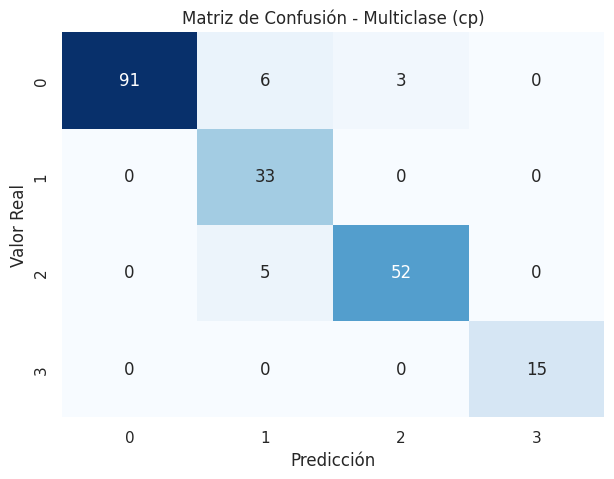

In [ ]:
conf_matrix = confusion_matrix(y_test_m, y_pred_m)

plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Matriz de Confusión - Multiclase ({target_multiclase})')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

Conclusiones de la Extensión Multiclase (Basadas en los Resultados de la Matriz de Confusión)

1. Alto Rendimiento General: Nuestro modelo de Random Forest demostró una excelente capacidad de discriminación en la tarea multiclase para predecir el tipo de dolor torácico (cp), logrando concentrar la gran mayoría de nuestros aciertos a lo largo de la diagonal principal de la matriz de confusión.
2. Predicción Perfecta en Clases Específicas: En nuestro análisis notamos que las clases 1 y 3 se predijeron con total precisión, alcanzando 33 y 15 aciertos respectivamente sin registrar ningún falso positivo ni falso negativo, lo que evidencia que estas categorías poseen características clínicas muy claras para el modelo.
3. Superposición Clínica Menor: Identificamos algunas confusiones naturales en la clase 0 (donde 6 muestras se predijeron como clase 1 y 3 como clase 2) y en la clase 2 (con 5 muestras confundidas hacia la clase 1), lo cual refleja la similitud sintomatológica que pueden presentar ciertos pacientes en la práctica real.
4. Valor Metodológico de la Extensión: Concluimos que incorporar este enfoque multiclase enriqueció significativamente nuestro proyecto, comprobando que los algoritmos de ensamblaje no solo nos sirven para problemas binarios, sino que también son muy capaces de modelar la complejidad de múltiples categorías diagnósticas con gran solidez.